# So sánh chỉ số tình trạng rừng (FCI) trong khu bảo tồn: Việt Nam, Mỹ, Úc (ForTy V2 Beta, 2017–2025)

Notebook này:
1. lấy khu bảo tồn của Việt Nam, Mỹ và Úc từ `WCMC/WDPA/current/polygons`, chỉ giữ `DESIG_ENG` thuộc
   `["Nature Reserve", "National Park", "Cultural and Historical Site"]`, rồi lấy **20 khu có diện tích đất liền lớn nhất** mỗi nước;
2. tính diện tích từng loại rừng ForTy V2 Beta theo năm 2017–2025 và chuyển đổi lớp 2017 → 2025 (cùng pipeline với dự án khu bảo tồn Việt Nam);
3. tính FCI 2017 → 2025, ΔFCI, xu hướng Theil–Sen và Mann–Kendall cho từng khu;
4. so sánh giữa các nước theo hai nhóm chỉ tiêu: **trạng thái** (FCI 2025) và **xu hướng** (ΔFCI), kèm khoảng tin cậy bootstrap, kiểm định hoán vị và xếp hạng;
5. vẽ bản đồ loại rừng 2017/2025 (có FCI), bản đồ thay đổi, biểu đồ diện tích cho từng khu, và bản đồ so sánh ΔFCI của mỗi nước;
6. xuất báo cáo `docs/index.html` (một file, ảnh nhúng sẵn).

Mọi kết quả trung gian lưu trong `outputs/` (areas, transitions, thumbs); chạy lại chỉ tính phần còn thiếu.

**Chuẩn bị:** Earth Engine đã đăng nhập (project `ee-hoangvietanh`). Kernel: `.venv` của thư mục này.

## 1. Cấu hình

In [1]:
import shutil, sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

CFG = {
    "PROJECT": "ee-hoangvietanh",
    "YEARS": list(range(2017, 2026)),
    "MAP_YEARS": [2017, 2025],
    "COUNTRIES": ["VNM", "USA", "AUS"],
    "DESIG_ENG": ["Nature Reserve", "National Park", "Cultural and Historical Site"],
    "TOP_N": 20,                                  # số khu lớn nhất (theo diện tích đất liền) mỗi nước
    "STATUS": ("Designated", "Inscribed"),       # bỏ khu "Proposed"
    "EXCLUDE_REALM": ("Marine",),                # bỏ khu thuần biển
    "AREA_SCALES": (10, 20, 30, 60, 100),        # độ phân giải tính diện tích (m); chỉ dùng mức thô hơn khi mức mịn bị lỗi
    "MAX_PIXELS": 2e7,        # bỏ qua các mức mà số pixel của khu vượt ngưỡng này (khu rất lớn ở 10 m chạy hàng chục phút rồi lỗi)
    "GEE_WORKERS": 6,
    "THUMB_DIMS": 900,
    "CHANGE_BIG_KM2": 3000,   # khu lớn hơn: bản đồ thay đổi tính từ pixel 30 m thay vì 10 m (diện tích vẫn theo AREA_SCALES)
    "SHOW_IN_NOTEBOOK": 2,    # số khu mỗi nước hiển thị trong notebook (báo cáo HTML luôn có tất cả)
    # Kết quả đã tính của dự án khu bảo tồn Việt Nam (cùng phương pháp): chép sang để không tính lại
    "REUSE_CACHE_FROM": Path(r"C:\Users\gfd\Documents\Claude\Projects\2026.10.25 nature forest alphaearth map\outputs"),
    "OUT": ROOT / "outputs",
    "PAGES_DIR": ROOT / "docs",
}
OUT = CFG["OUT"]
for d in ("areas", "transitions", "thumbs", "maps", "charts", "compare"):
    (OUT / d).mkdir(parents=True, exist_ok=True)

In [2]:
import ee
import pandas as pd
from IPython.display import Image, Markdown, display

from fortypa import charts, compare, compare_report, gee, index

pd.set_option("display.max_rows", 300, "display.width", 200)
gee.init(CFG["PROJECT"])
print("Earth Engine OK")

Earth Engine OK


## 2. Chọn khu bảo tồn

Mỗi nước: `ISO3`, trạng thái Designated/Inscribed, bỏ khu thuần biển, rồi
`fc.filter(ee.Filter.inList("DESIG_ENG", ["Nature Reserve", "National Park", "Cultural and Historical Site"]))`.
WDPA lưu một số khu thành nhiều mảnh cùng `SITE_ID` (gặp ở Úc): các mảnh được gộp lại thành một khu. Sau đó giữ 20 khu có
diện tích đất liền (`GIS_AREA − GIS_M_AREA`) lớn nhất; cột `RANK` là thứ hạng diện tích trong nước.

In [3]:
fcs, tables = [], []
for iso in CFG["COUNTRIES"]:
    fc_i, df_i = gee.select_pas(iso, desig_eng=CFG["DESIG_ENG"], status=CFG["STATUS"],
                                exclude_realm=CFG["EXCLUDE_REALM"], top_n=CFG["TOP_N"])
    fcs.append(fc_i)
    tables.append(df_i)
fc = fcs[0]
for f in fcs[1:]:
    fc = fc.merge(f)
pas = pd.concat(tables, ignore_index=True)
pas.to_csv(OUT / "khu_bao_ton.csv", index=False, encoding="utf-8-sig")
display(pas.groupby(["ISO3", "DESIG_ENG"]).size().rename("số khu").to_frame())
display(pas.groupby("ISO3").LAND_KM2.agg(["sum", "min", "max"]).round(0))
pas[["ISO3", "RANK", "SITE_ID", "NAME", "DESIG_ENG", "IUCN_CAT", "REALM", "PARCELS", "LAND_KM2"]]

số khu
ISO3 DESIG_ENG                           
AUS  National Park                     15
     Nature Reserve                     5
USA  National Park                     20
VNM  Cultural and Historical Site       1
     National Park                     10
     Nature Reserve                     9

,sum,min,max
ISO3,,,
AUS,216672.0,5688.0,36054.0
USA,144400.0,1646.0,32168.0
VNM,11972.0,373.0,1216.0


,ISO3,RANK,SITE_ID,NAME,DESIG_ENG,IUCN_CAT,REALM,PARCELS,LAND_KM2
0,VNM,1,10345,Phong Nha-Kẻ Bàng,National Park,II,Terrestrial,1,1216.089166
1,VNM,2,18033,Yok Don,National Park,II,Terrestrial,1,1063.843203
2,VNM,3,61595,Pù Mát,National Park,II,Terrestrial,1,971.043112
3,VNM,4,303066,Sông Thanh,Nature Reserve,Not Reported,Terrestrial,1,885.468431
4,VNM,5,303072,Cát Tiên,National Park,II,Terrestrial,1,698.626852
5,VNM,6,10380,Chư Yang Sin,National Park,II,Terrestrial,1,602.927220
6,VNM,7,555594129,Văn hóa Đồng Nai,Nature Reserve,Not Reported,Terrestrial,1,590.855493
7,VNM,8,10375,Vũ Quang,National Park,II,Terrestrial,1,588.474361
8,VNM,9,12171,Chư Mom Ray,National Park,II,Terrestrial,1,526.473362
9,VNM,10,303067,Bidoup-Núi Bà,National Park,Not Reported,Terrestrial,1,522.758861


### Dùng lại kết quả đã tính

Các khu của Việt Nam đã được tính trong dự án khu bảo tồn Việt Nam bằng đúng phương pháp này (cùng tên file cache theo
`SITE_ID`). Ô dưới chép các file còn thiếu sang `outputs/`; khu nào không có trong dự án cũ sẽ được tính trên GEE.

In [4]:
src = CFG["REUSE_CACHE_FROM"]
copied = 0
if src and Path(src).exists():
    ids = set(pas.SITE_ID.astype(str))
    for sub in ("areas", "transitions", "thumbs"):
        for f in (Path(src) / sub).glob("*"):
            if f.name.split("_")[0] in ids and not (OUT / sub / f.name).exists():
                shutil.copy2(f, OUT / sub / f.name)
                copied += 1
print(f"Đã chép {copied} file cache")

Đã chép 0 file cache


## 3. Diện tích từng loại rừng theo năm

Mỗi khu một request cho cả 9 năm (`frequencyHistogram`, hệ UTM của khu, 10 m). Các khu của Mỹ và Úc rộng hàng chục nghìn km²;
khu nào có số pixel ở 10 m vượt `MAX_PIXELS` thì bắt đầu ở độ phân giải thô hơn, và khi một mức bị lỗi thì tự chuyển sang
mức kế tiếp (20, 30, 60, 100 m). Độ phân giải đã dùng ghi ở cột `scale_m`.

In [5]:
t0 = time.time()
areas, failed = gee.compute_areas(fc, pas, CFG["YEARS"], OUT / "areas", scales=CFG["AREA_SCALES"],
                                  workers=CFG["GEE_WORKERS"], max_pixels=CFG["MAX_PIXELS"])
print(f"Xong sau {time.time() - t0:.0f}s; lỗi: {len(failed)} khu")
areas = areas[areas.SITE_ID.isin(pas.SITE_ID)]
long = areas.merge(pas[["ISO3", "SITE_ID", "NAME", "DESIG_ENG"]], on="SITE_ID")
long.to_csv(OUT / "dien_tich_loai_rung_dai.csv", index=False, encoding="utf-8-sig")
long.pivot_table(index=["ISO3", "SITE_ID", "NAME", "year"], columns="label", values="area_ha", aggfunc="sum") \
    .fillna(0).to_csv(OUT / "dien_tich_loai_rung.csv", encoding="utf-8-sig")
display(areas.groupby("SITE_ID").scale_m.max().value_counts().rename("số khu theo độ phân giải (m)").to_frame())

Diện tích: 60 PA lấy từ cache, 0 PA cần tính trên GEE
Xong sau 0s; lỗi: 0 khu


,số khu theo độ phân giải (m)
scale_m,
20,23
10,22
30,10
60,5


### Chuyển đổi lớp 2017 → 2025

Diện tích từng cặp "lớp cũ → lớp mới" (`frequencyHistogram` của ảnh lớp2017×10 + lớp2025), cùng cách lùi độ phân giải.

In [6]:
transitions, failed_tr = gee.compute_transitions(fc, pas, CFG["YEARS"], OUT / "transitions",
                                                 scales=CFG["AREA_SCALES"], workers=CFG["GEE_WORKERS"],
                                                 max_pixels=CFG["MAX_PIXELS"])
transitions = transitions[transitions.SITE_ID.isin(pas.SITE_ID)]
lab = gee.CLASSES.set_index("value").label
(transitions.assign(tu_lop=transitions["from"].map(lab), sang_lop=transitions["to"].map(lab),
                    loai_thay_doi=transitions.change.map(gee.CHANGES.set_index("code").label))
 .merge(pas[["ISO3", "SITE_ID", "NAME"]], on="SITE_ID")
 .to_csv(OUT / "chuyen_doi_lop_2017_2025.csv", index=False, encoding="utf-8-sig"))
print(f"{transitions.SITE_ID.nunique()} khu; lỗi: {len(failed_tr)}")

Chuyển đổi lớp: 60 PA lấy từ cache, 0 PA cần tính trên GEE
60 khu; lỗi: 0


## 4. Chỉ số FCI của từng khu

FCI<sub>t</sub> = 100 × Σ w·A / ΣA với trọng số `index.WEIGHTS` (nguyên sinh trưởng thành 1,0; nguyên sinh đang phục hồi 0,8;
tái sinh tự nhiên 0,6; rừng trồng 0,3; rừng trồng thâm canh 0,2; cây công nghiệp 0,1; đất khác 0). ΔFCI = FCI 2025 − FCI 2017.
Khu **suy giảm** / **phục hồi** khi |ΔFCI| ≥ 1 điểm **và** Mann–Kendall p < 0,05; còn lại **ổn định / không rõ**.

Bảng chỉ tiêu từng khu (`compare.pa_indicators`) thêm: ΔFCI so với FCI 2017 (%), FCI tính riêng trên phần có rừng,
tỷ lệ rừng & cây, thay đổi ròng rừng tự nhiên và phần diện tích đổi lớp.

In [7]:
Y0, Y1 = CFG["YEARS"][0], CFG["YEARS"][-1]
fci = index.fci_index(areas, CFG["YEARS"])
fci_years = index.fci_series(areas, CFG["YEARS"]).round(2)
ind = compare.pa_indicators(pas, areas, fci, transitions, CFG["YEARS"])
ind.merge(fci_years.add_prefix("fci_nam_"), left_on="SITE_ID", right_index=True) \
   .to_csv(OUT / "chi_so_FCI.csv", index=False, encoding="utf-8-sig")
same = ((fci.dfci > 0) == (fci.trend > 0)).mean()
print(f"ΔFCI cùng dấu với xu hướng 9 năm: {same:.0%} số khu")
display(pd.crosstab(ind.ISO3, ind.verdict))
ind[["ISO3", "RANK", "NAME", f"fci_{Y0}", f"fci_{Y1}", "dfci", "dfci_rel", "mk_p", "verdict",
     f"fci_forest_{Y1}", "natural_change_pct", "changed_pct", "scale_m"]].round(3)

ΔFCI cùng dấu với xu hướng 9 năm: 88% số khu


verdict,Suy giảm,Ổn định / không rõ
ISO3,,
AUS,4,16
USA,1,19
VNM,0,20


,ISO3,RANK,NAME,fci_2017,fci_2025,dfci,dfci_rel,mk_p,verdict,fci_forest_2025,natural_change_pct,changed_pct,scale_m
0,VNM,1,Phong Nha-Kẻ Bàng,97.536,97.504,-0.032,-0.033,0.029,Ổn định / không rõ,97.790,-0.028,0.136,10
1,VNM,2,Yok Don,57.800,57.748,-0.052,-0.090,0.000,Ổn định / không rõ,62.397,-0.086,0.188,10
2,VNM,3,Pù Mát,98.912,98.903,-0.009,-0.009,0.000,Ổn định / không rõ,99.320,-0.014,0.029,10
3,VNM,4,Sông Thanh,92.442,92.202,-0.240,-0.259,0.001,Ổn định / không rõ,94.059,-0.310,0.992,10
4,VNM,5,Cát Tiên,78.569,78.550,-0.018,-0.023,0.029,Ổn định / không rõ,81.847,-0.010,0.124,10
5,VNM,6,Chư Yang Sin,80.869,80.828,-0.041,-0.051,0.076,Ổn định / không rõ,81.901,-0.050,0.118,10
6,VNM,7,Văn hóa Đồng Nai,81.028,81.008,-0.020,-0.025,0.175,Ổn định / không rõ,83.463,0.063,0.907,10
7,VNM,8,Vũ Quang,93.607,93.198,-0.409,-0.437,0.076,Ổn định / không rõ,96.285,-0.735,1.286,10
8,VNM,9,Chư Mom Ray,84.746,84.777,0.031,0.036,0.005,Ổn định / không rõ,87.107,0.059,0.149,10
9,VNM,10,Bidoup-Núi Bà,76.482,76.526,0.044,0.057,0.000,Ổn định / không rõ,77.851,0.015,0.329,10


## 5. So sánh giữa các nước

- **Trạng thái:** FCI 2025 (trung vị các khu), FCI phần có rừng 2025 (gộp).
- **Xu hướng:** ΔFCI trung vị, ΔFCI so với FCI 2017 (trung vị, %), % khu có ΔFCI âm, thay đổi ròng rừng tự nhiên (gộp).

“Gộp” coi 20 khu của một nước là một vùng (khu lớn nặng ký hơn); “trung vị” cho mỗi khu một phiếu. Khoảng tin cậy 95% của
ΔFCI trung vị: bootstrap 10.000 lần. Khác biệt giữa hai nước: kiểm định hoán vị 20.000 lần. Xếp hạng: hạng 1–3 theo từng chỉ
tiêu, điểm trạng thái và điểm xu hướng là trung bình hạng trong nhóm, điểm chung là trung bình hai điểm (thấp = tốt).

In [8]:
series = compare.country_series(pas, areas, CFG["YEARS"])
table = compare.country_table(ind, series, CFG["YEARS"])
rank, groups = compare.ranking(table, CFG["YEARS"])
tests = compare.pairwise_tests(ind)
series.to_csv(OUT / "FCI_theo_nuoc_theo_nam.csv", index=False, encoding="utf-8-sig")
table.to_csv(OUT / "so_sanh_nuoc.csv", index=False, encoding="utf-8-sig")
rank.to_csv(OUT / "xep_hang_nuoc.csv", encoding="utf-8-sig")
tests.to_csv(OUT / "kiem_dinh_hoan_vi.csv", index=False, encoding="utf-8-sig")
display(table.set_index("country").T.round(3))
display(rank)
tests.round(4)

country,Việt Nam,Mỹ,Úc
ISO3,VNM,USA,AUS
n,20,20,20
land_km2,11971.809191,144400.492252,216671.963159
fci_pooled_2017,81.146619,23.44019,16.699055
fci_pooled_2025,81.080966,23.331125,15.898134
dfci_pooled,-0.065653,-0.109065,-0.800921
fci_median_2025,85.273846,24.882377,0.839602
fci_forest_pooled_2025,85.367496,96.726018,93.036738
forest_pct_pooled_2025,94.978734,24.120837,17.088017
dfci_median,-0.019229,-0.045097,-0.325076


,FCI 2025 (trung vị các khu),FCI phần có rừng 2025 (gộp),ΔFCI 2017→2025 (trung vị các khu),"ΔFCI so với FCI 2017 (trung vị, %)",% khu có ΔFCI âm,"Thay đổi ròng rừng tự nhiên (gộp, %)",Điểm trạng thái,Điểm xu hướng,Điểm chung,Hạng chung
country,,,,,,,,,,
Việt Nam,1.0,3.0,1.0,1.0,1.0,1.0,2.0,1.0,1.50,1
Mỹ,2.0,1.0,2.0,2.0,2.0,2.0,1.5,2.0,1.75,2
Úc,3.0,2.0,3.0,3.0,3.0,3.0,2.5,3.0,2.75,3


,a,b,median_a,median_b,diff,p
0,Việt Nam,Mỹ,-0.0192,-0.0451,0.0259,0.2573
1,Việt Nam,Úc,-0.0192,-0.3251,0.3058,0.0042
2,Mỹ,Úc,-0.0451,-0.3251,0.2800,0.0966


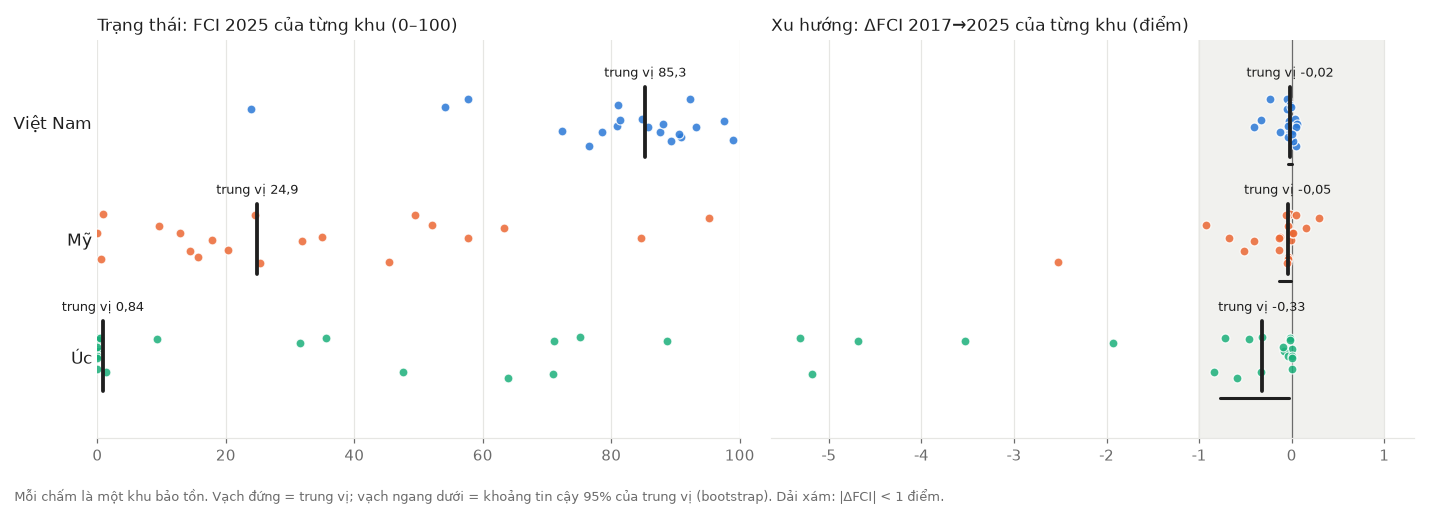

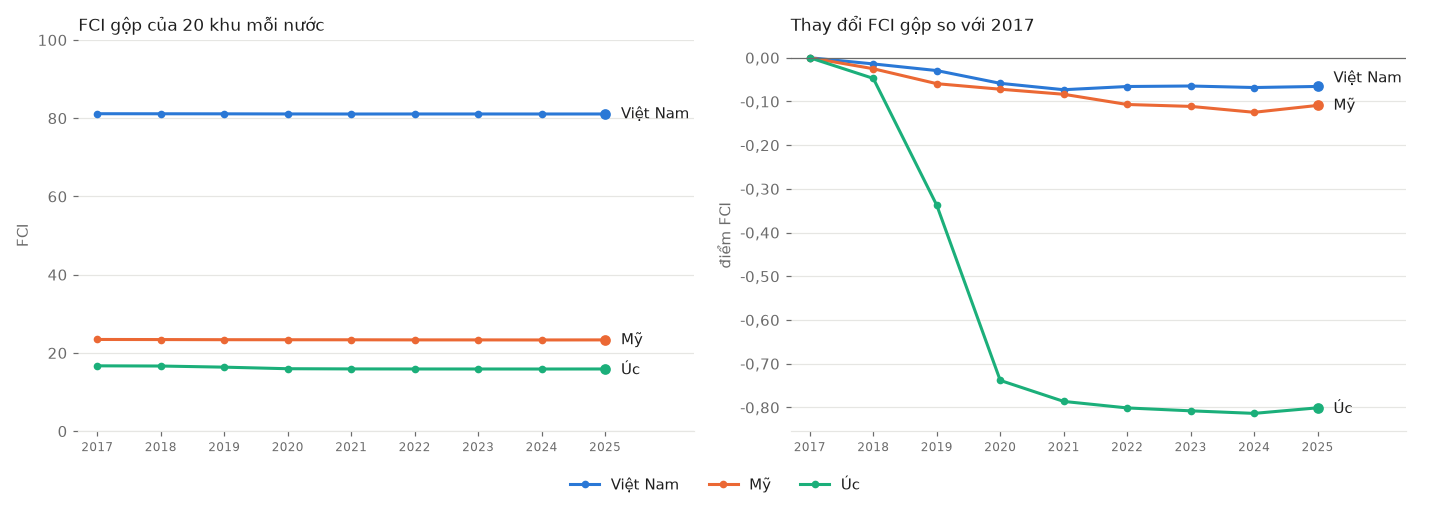

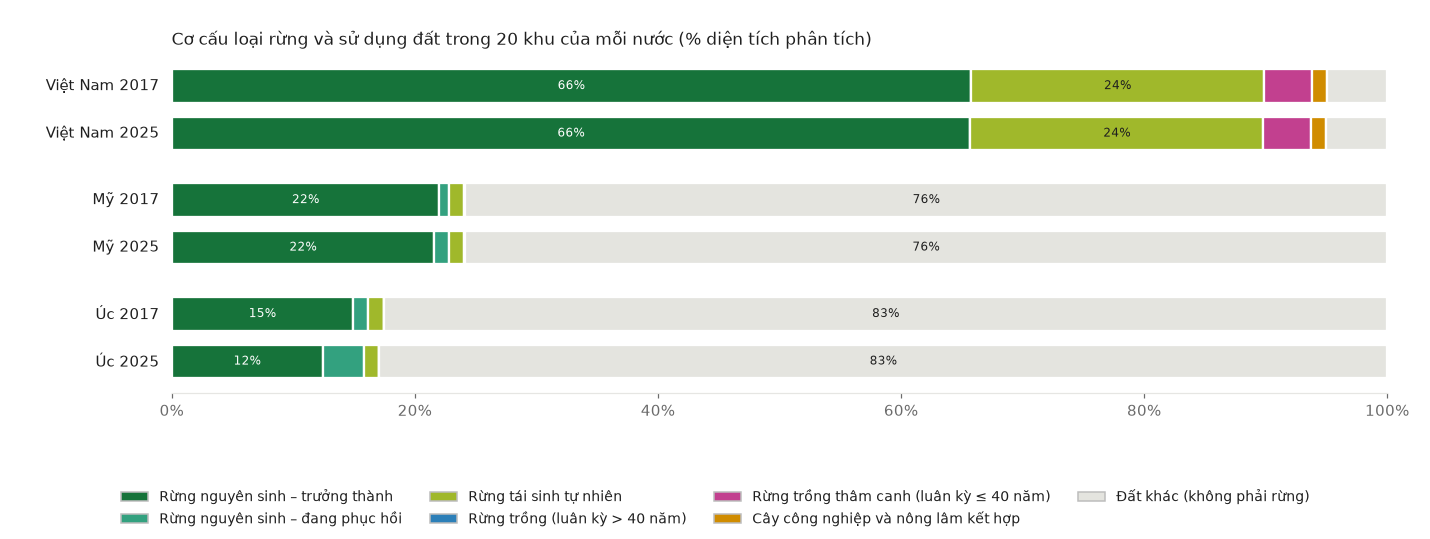

In [9]:
ci = {r.ISO3: (r.dfci_ci_lo, r.dfci_ci_hi) for r in table.itertuples()}
country_figs = {
    "state_trend": charts.state_trend_figure(ind, ci, CFG["YEARS"], OUT / "compare" / "trang_thai_xu_huong.png",
                                             min_delta=index.MIN_DELTA),
    "series": charts.series_figure(series, CFG["YEARS"], OUT / "compare" / "FCI_theo_nam.png"),
    "composition": charts.composition_figure(areas, pas, CFG["YEARS"], OUT / "compare" / "co_cau_loai_rung.png"),
}
for f in country_figs.values():
    display(Image(filename=str(f)))

### Bản đồ so sánh ΔFCI

Mỗi nước một bản đồ: các khu tô màu theo ΔFCI 2017 → 2025 (đỏ giảm, xanh tăng, xám gần như không đổi), số là thứ hạng diện tích.

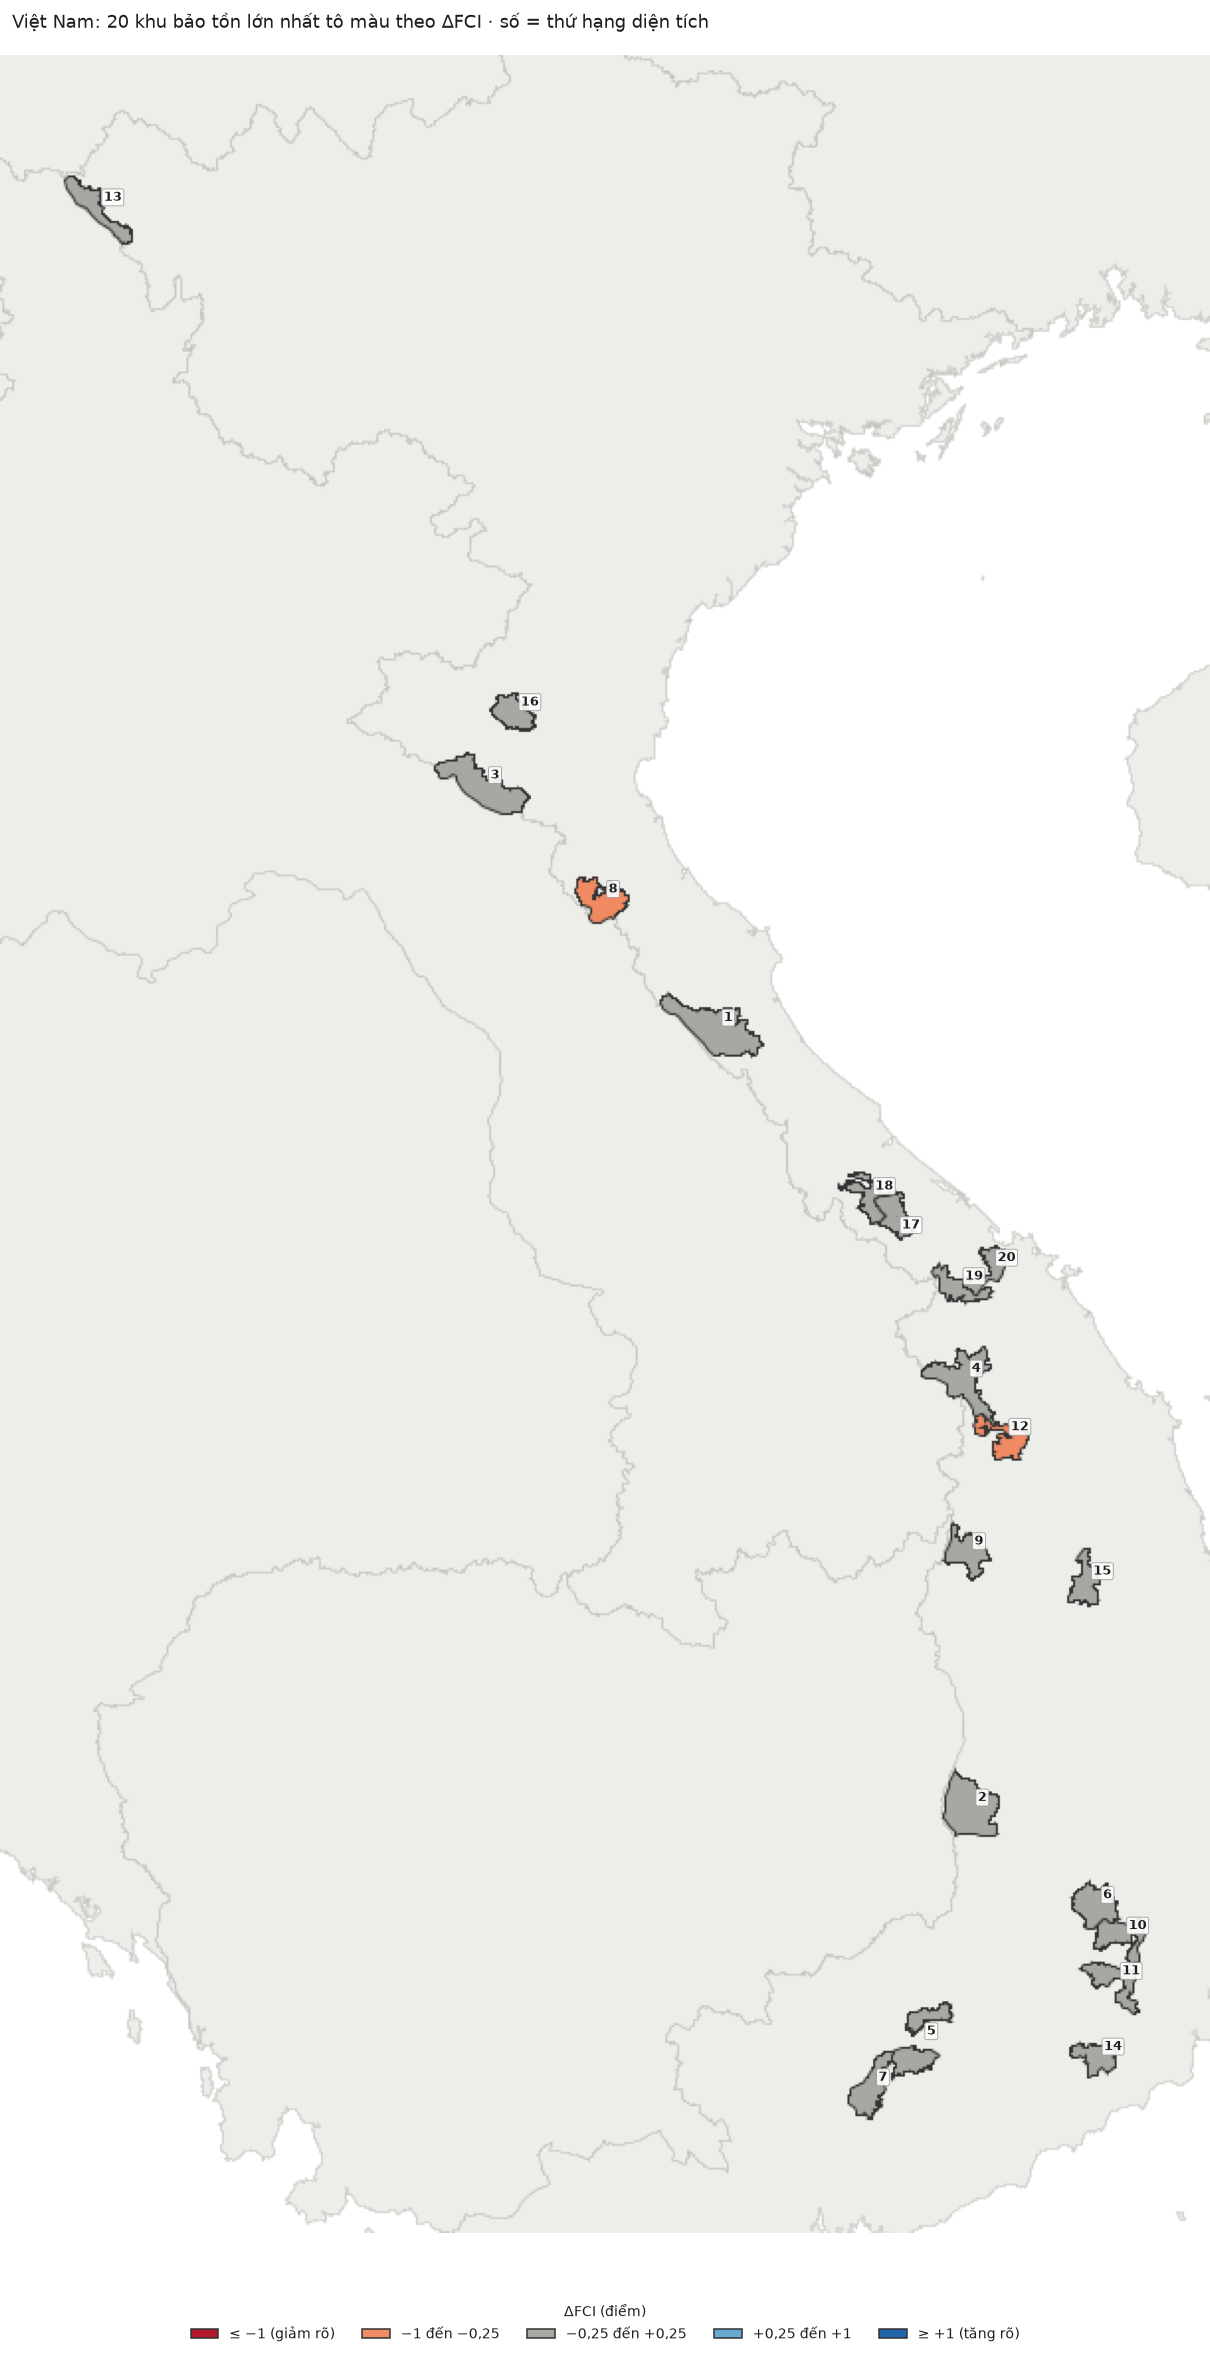

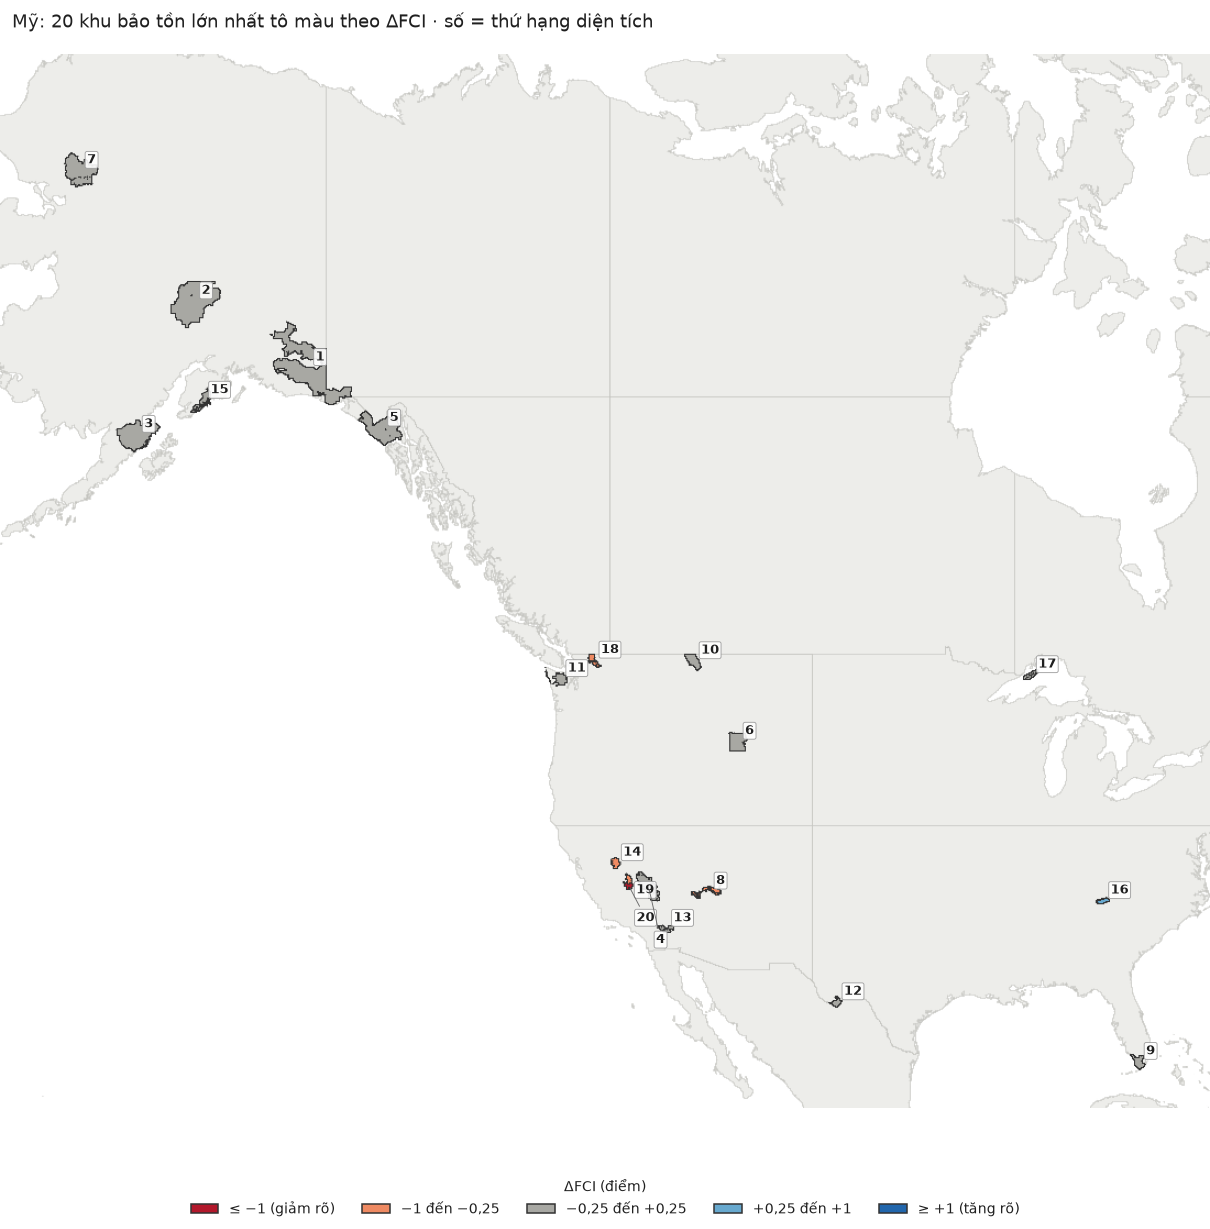

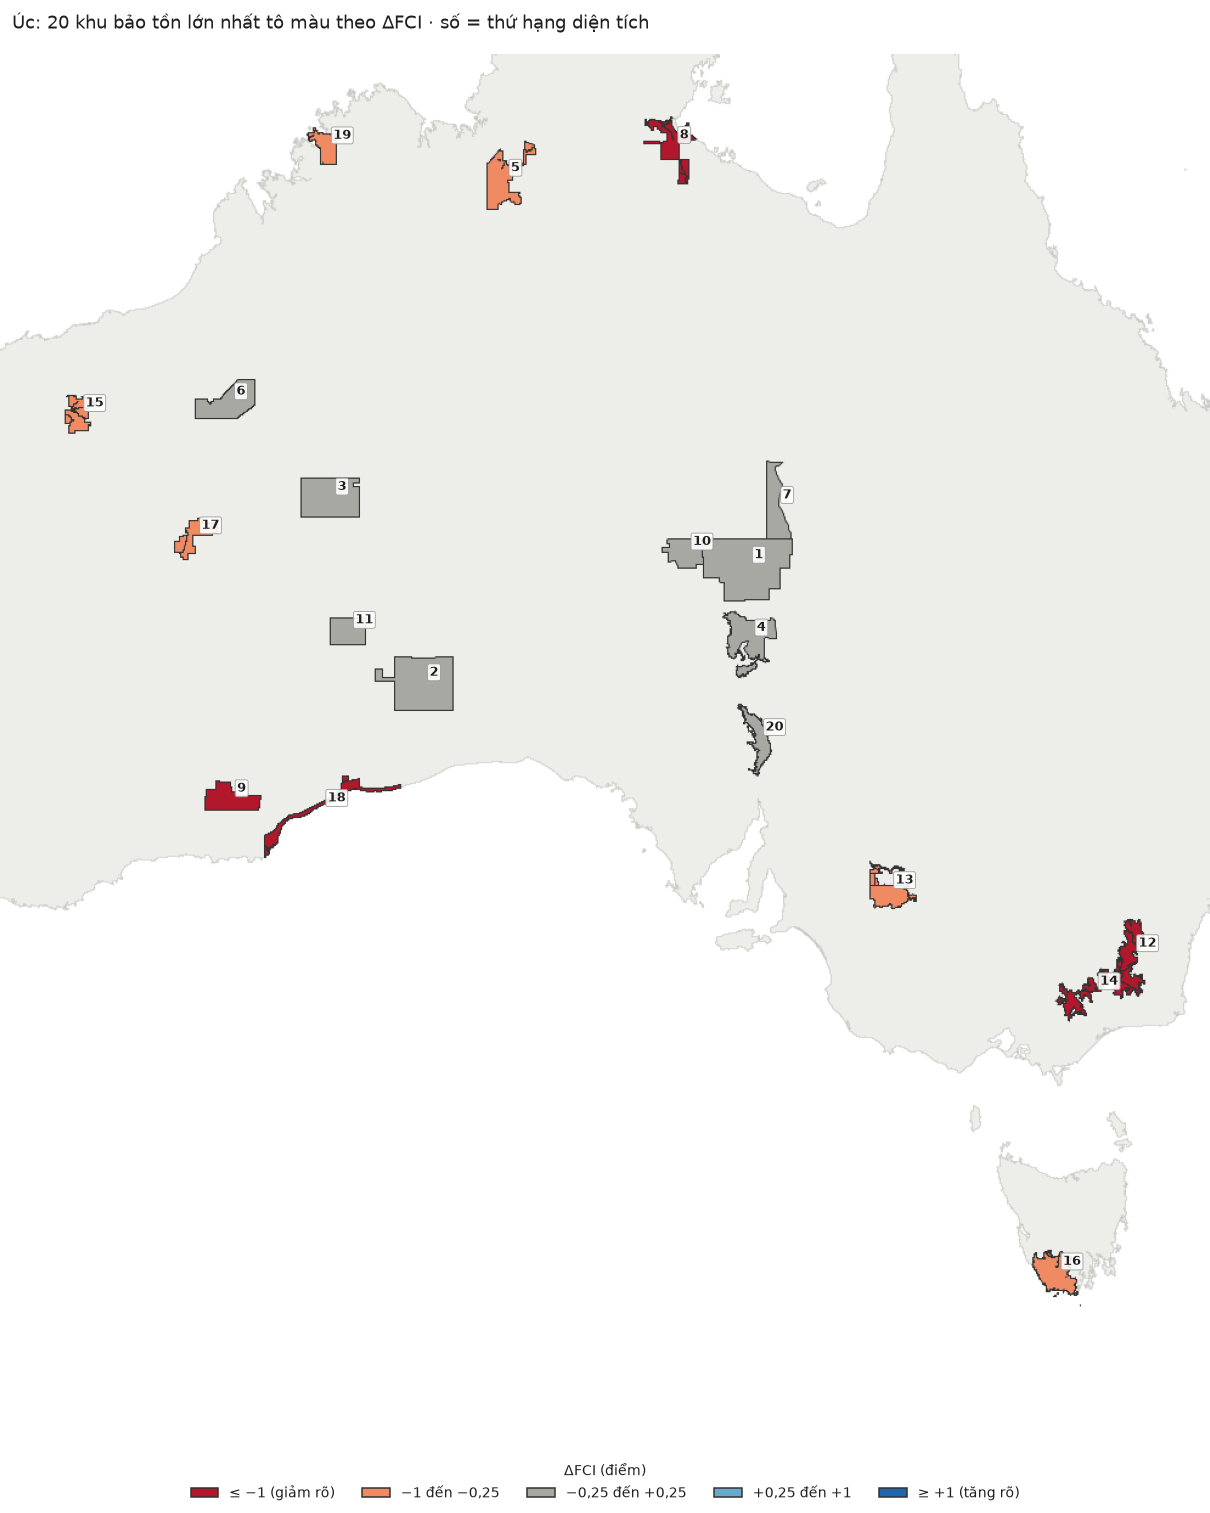

In [10]:
dfci_by_site = ind.set_index("SITE_ID").dfci
names = compare.COUNTRIES.set_index("ISO3").name
overview = {}
for iso, fc_i in zip(CFG["COUNTRIES"], fcs):
    p_i = pas[pas.ISO3 == iso]
    colors = {s: charts.dfci_color(dfci_by_site[s]) for s in p_i.SITE_ID if s in dfci_by_site.index}
    png = OUT / "thumbs" / f"overview_{iso}.png"
    extent = gee.overview_thumb(fc_i, colors, png, dims=1100)
    overview[iso] = charts.overview_figure(names[iso], png, extent, p_i, OUT / "compare" / f"ban_do_dFCI_{iso}.png")
    display(Image(filename=str(overview[iso])))

## 6. Bản đồ và biểu đồ của từng khu

- Bản đồ loại rừng 2017 và 2025 (`getThumbURL`, EPSG:3857), tiêu đề có FCI từng năm và ΔFCI.
- Bản đồ thay đổi 2017 → 2025: so lớp từng pixel, gộp 4 loại thay đổi (`gee.CHANGES`), tải theo ô bằng `ee.data.computePixels`
  rồi gộp dần 4×4. Màu = loại thay đổi chiếm ưu thế, độ đậm = căn bậc hai tỷ lệ pixel đổi lớp. Khu lớn hơn
  `CHANGE_BIG_KM2` tính từ pixel 30 m để số request không quá lớn.
- Biểu đồ đường diện tích từng loại rừng và thay đổi so với 2017.

In [11]:
fci_by = fci.set_index("SITE_ID")
thumbs = gee.download_thumbs(fc, pas, CFG["MAP_YEARS"], OUT / "thumbs", dims=CFG["THUMB_DIMS"],
                             workers=CFG["GEE_WORKERS"])
figures = {}
for pa in pas.itertuples():
    out = OUT / "maps" / f"{pa.SITE_ID}_{CFG['MAP_YEARS'][0]}_{CFG['MAP_YEARS'][-1]}.png"
    fy = ({Y0: fci_by.loc[pa.SITE_ID, f"fci_{Y0}"], Y1: fci_by.loc[pa.SITE_ID, f"fci_{Y1}"]}
          if pa.SITE_ID in fci_by.index else None)
    charts.map_figure(pa, {y: thumbs.get((pa.SITE_ID, y)) for y in CFG["MAP_YEARS"]}, CFG["MAP_YEARS"], out, fci=fy)
    figures[pa.SITE_ID] = {"map": out}
print(f"{len(figures)} bản đồ loại rừng")

Ảnh bản đồ: 120/120


60 bản đồ loại rừng


In [12]:
t0 = time.time()
change_maps = gee.download_change_maps(fc, pas, CFG["YEARS"], OUT / "thumbs", dims=CFG["THUMB_DIMS"],
                                       big_km2=CFG["CHANGE_BIG_KM2"])
for pa in pas.itertuples():
    if pa.SITE_ID in change_maps:
        figures[pa.SITE_ID]["change"] = charts.change_figure(
            pa, change_maps[pa.SITE_ID], transitions[transitions.SITE_ID == pa.SITE_ID], CFG["YEARS"],
            OUT / "maps" / f"{pa.SITE_ID}_change_{Y0}_{Y1}.png",
            map_scale=30 if pa.GIS_AREA > CFG["CHANGE_BIG_KM2"] else 10)
    if not areas[areas.SITE_ID == pa.SITE_ID].empty:
        figures[pa.SITE_ID]["chart"] = charts.area_chart(pa, areas[areas.SITE_ID == pa.SITE_ID], CFG["YEARS"],
                                                         OUT / "charts" / f"{pa.SITE_ID}.png")
print(f"Xong sau {time.time() - t0:.0f}s")

Bản đồ thay đổi: 60/60


Xong sau 44s


### Việt Nam · 1. Phong Nha-Kẻ Bàng (National Park, WDPA 10345)

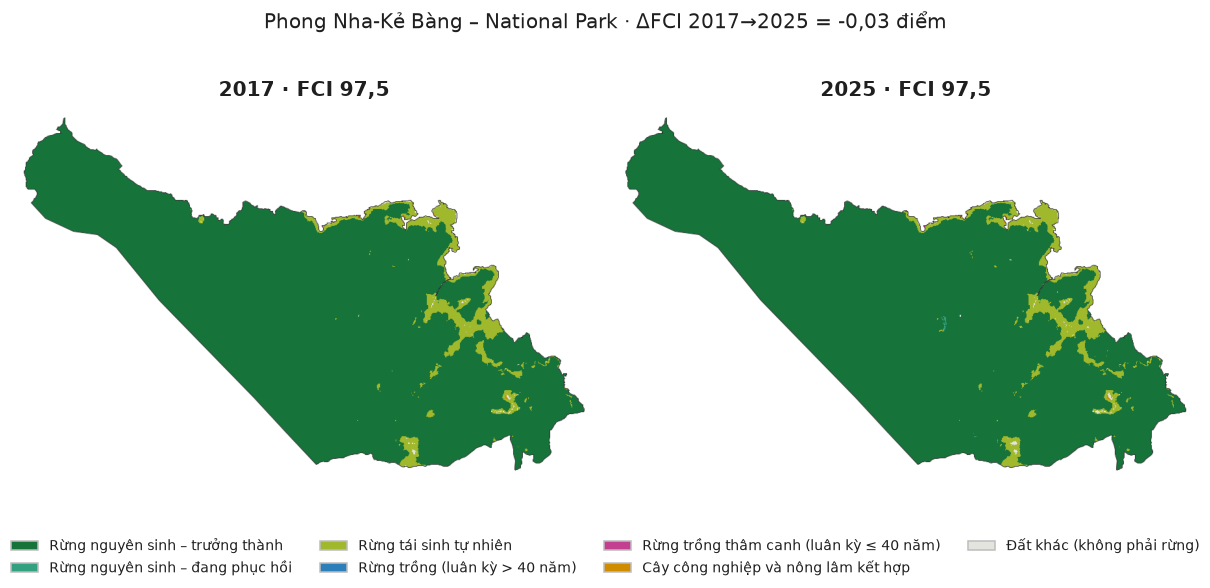

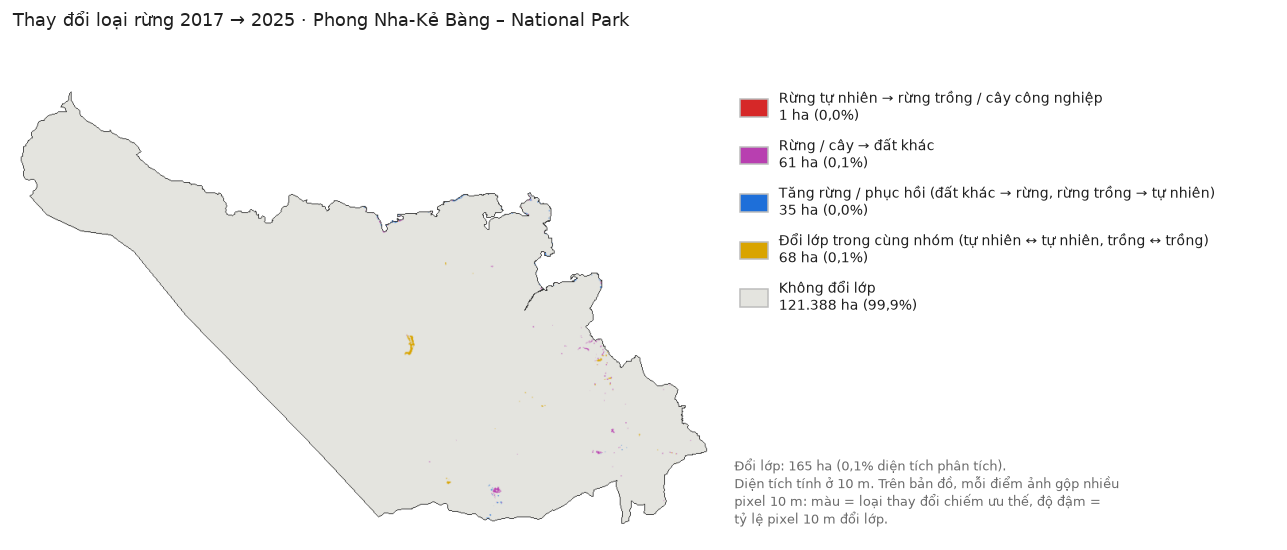

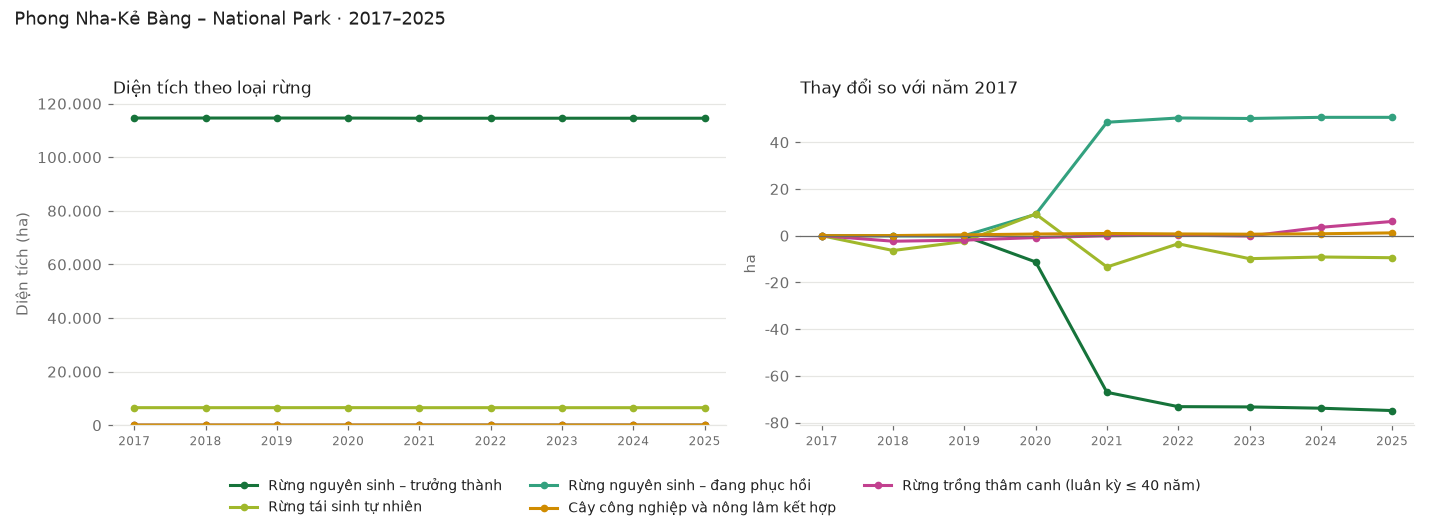

### Việt Nam · 2. Yok Don (National Park, WDPA 18033)

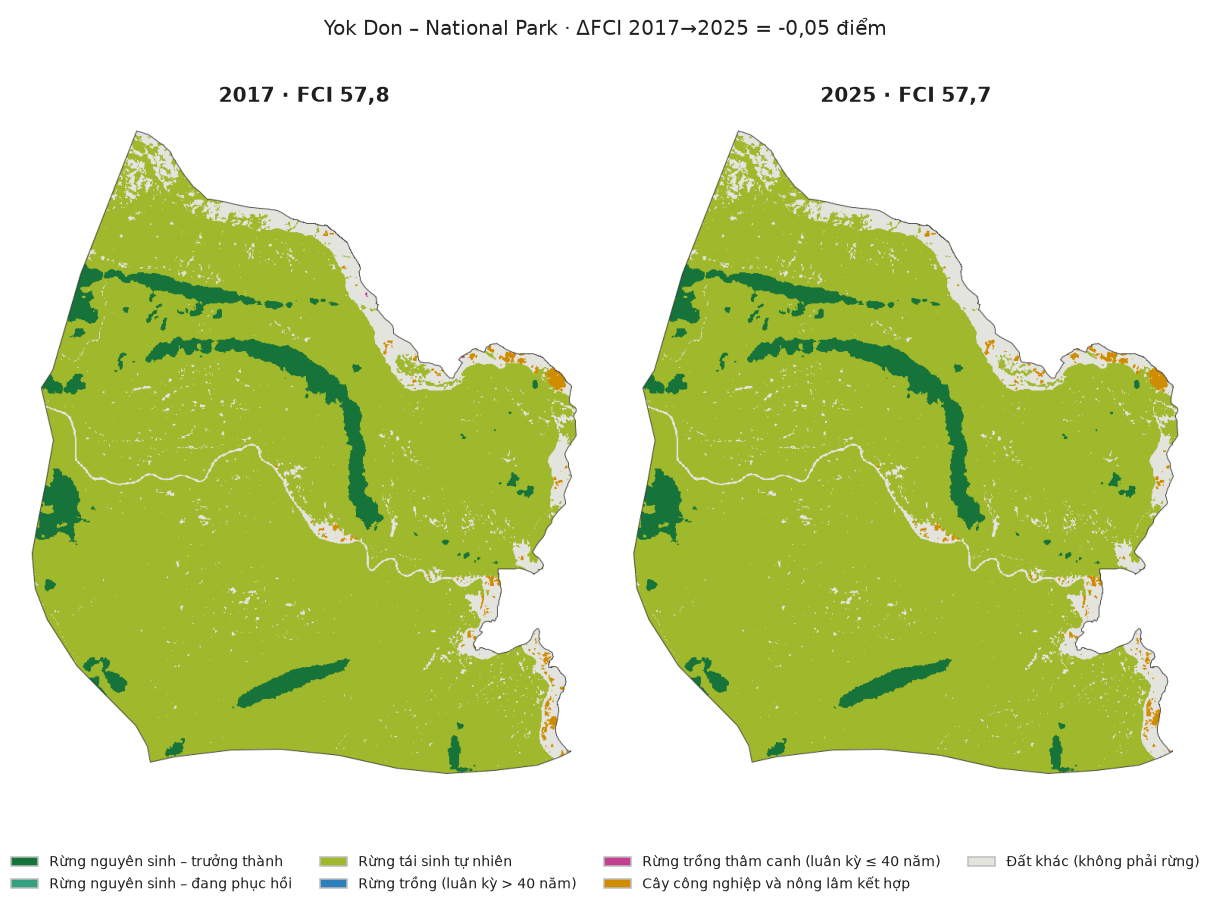

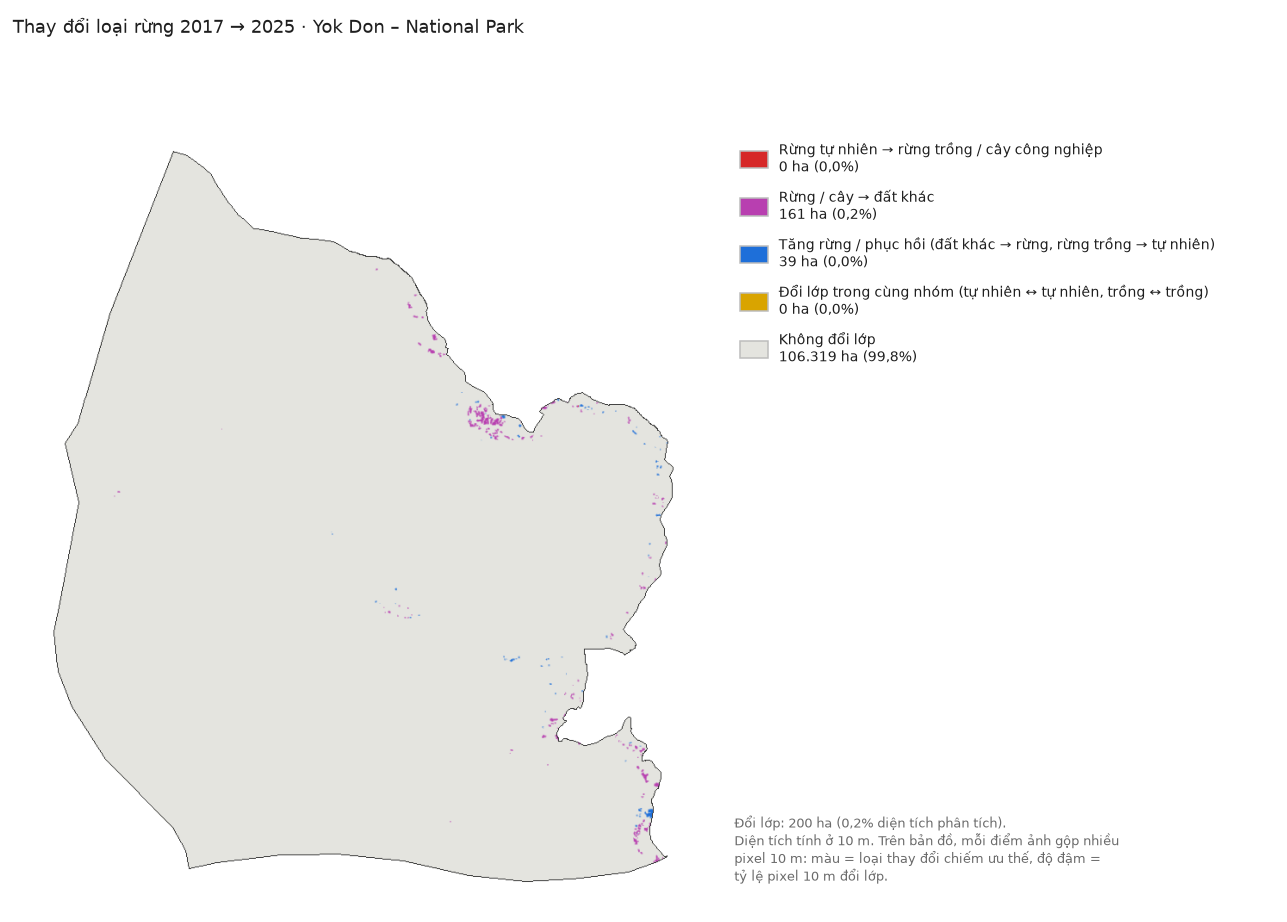

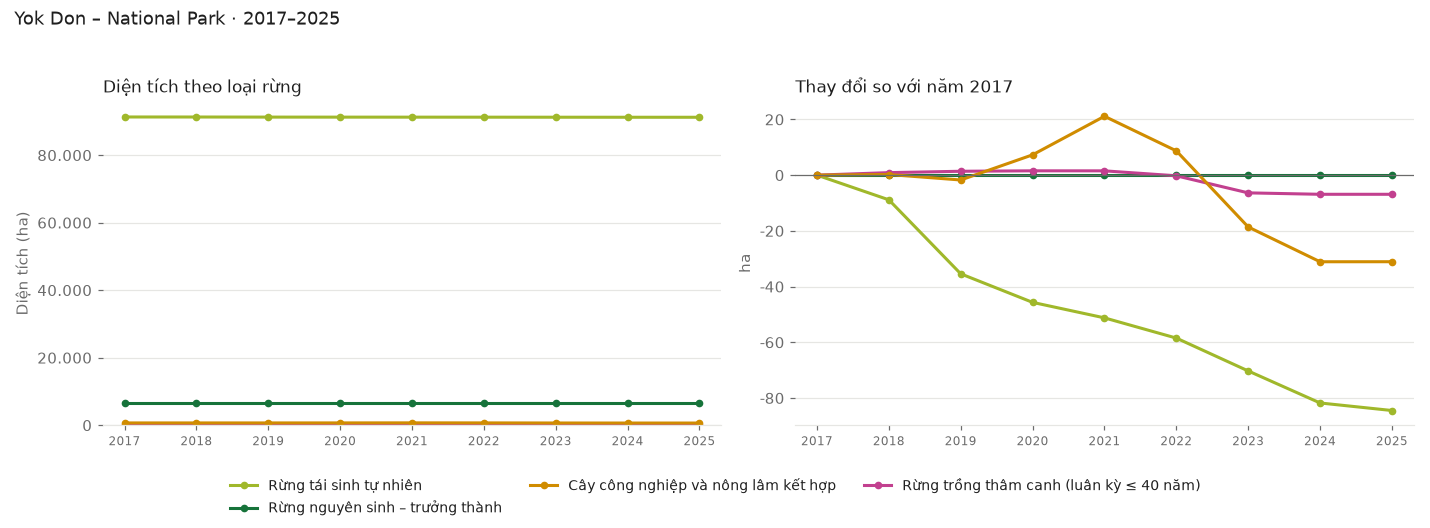

### Mỹ · 1. Wrangell-St. Elias (National Park, WDPA 22490)

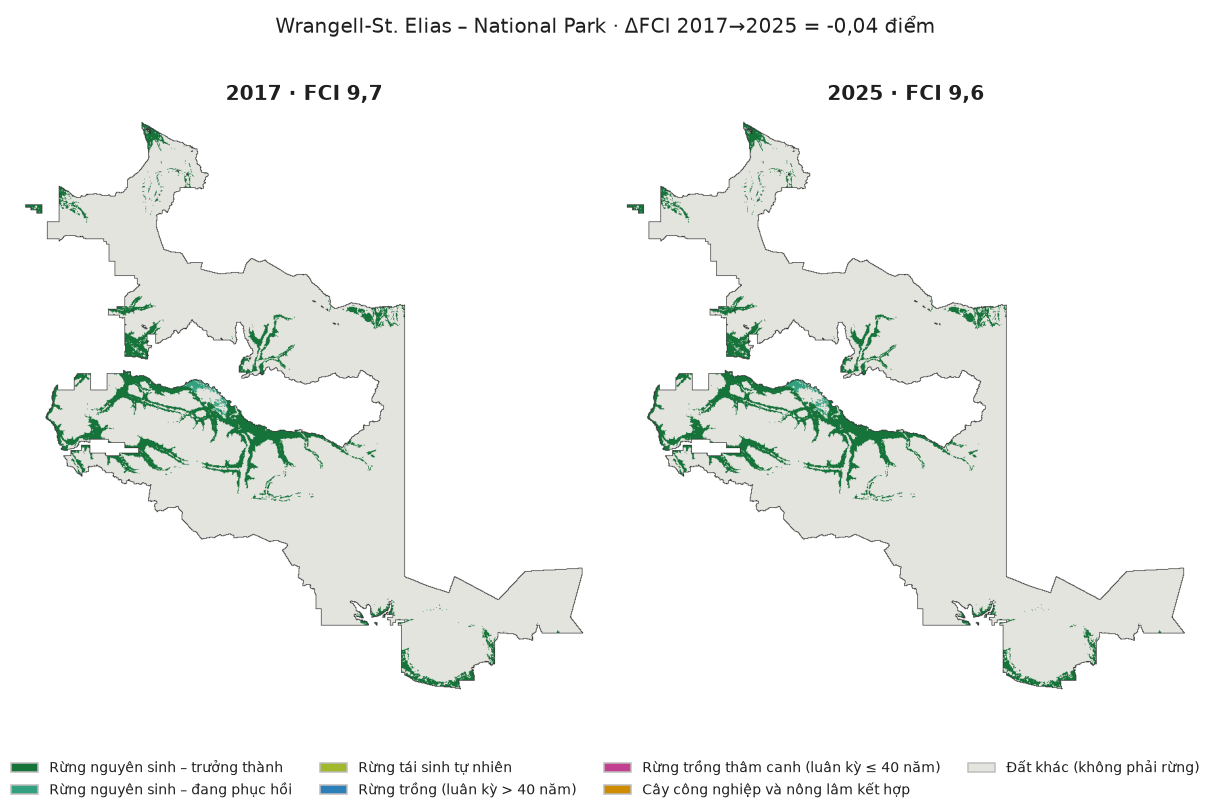

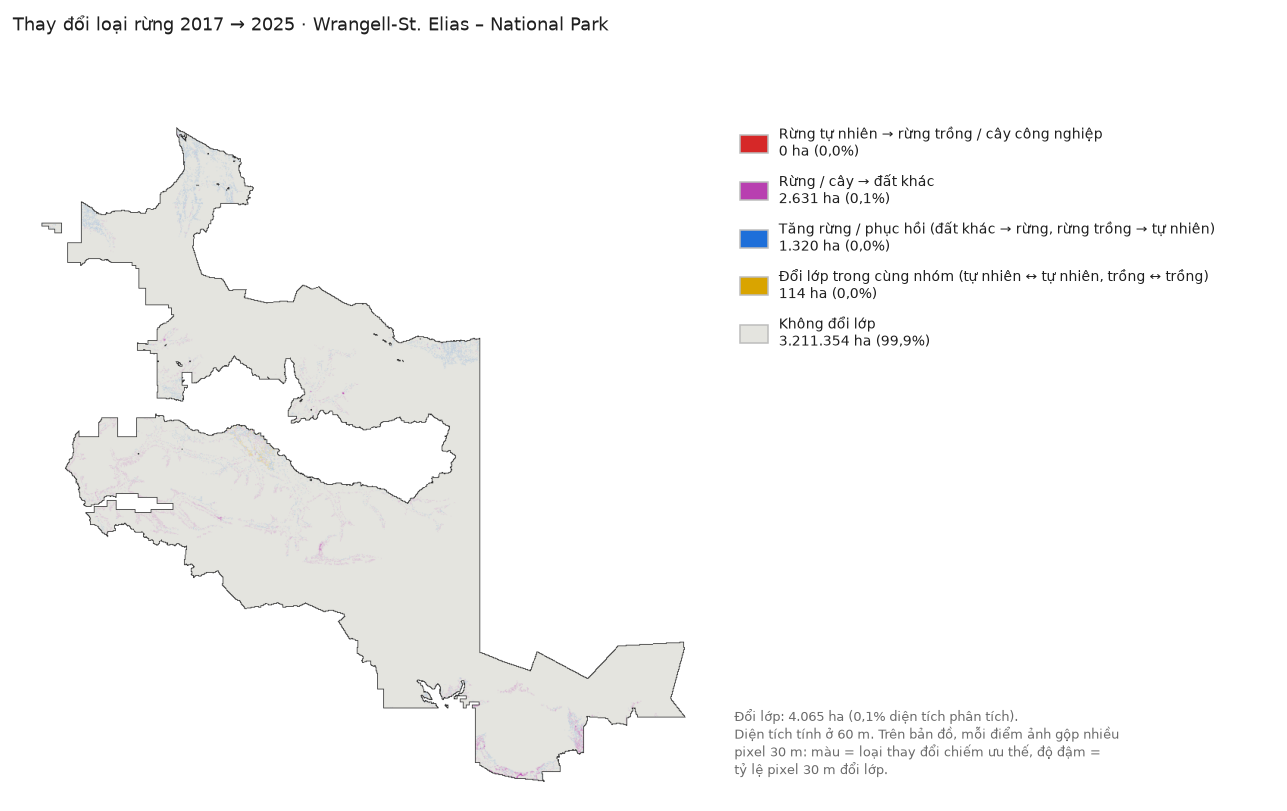

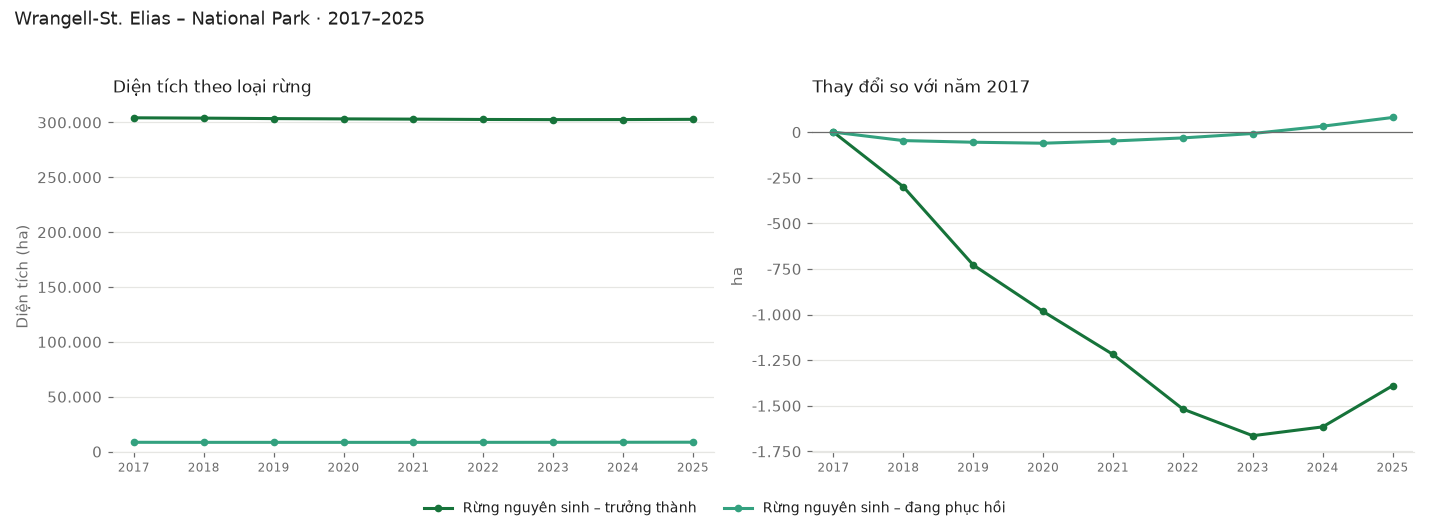

### Mỹ · 2. Denali (National Park, WDPA 555679194)

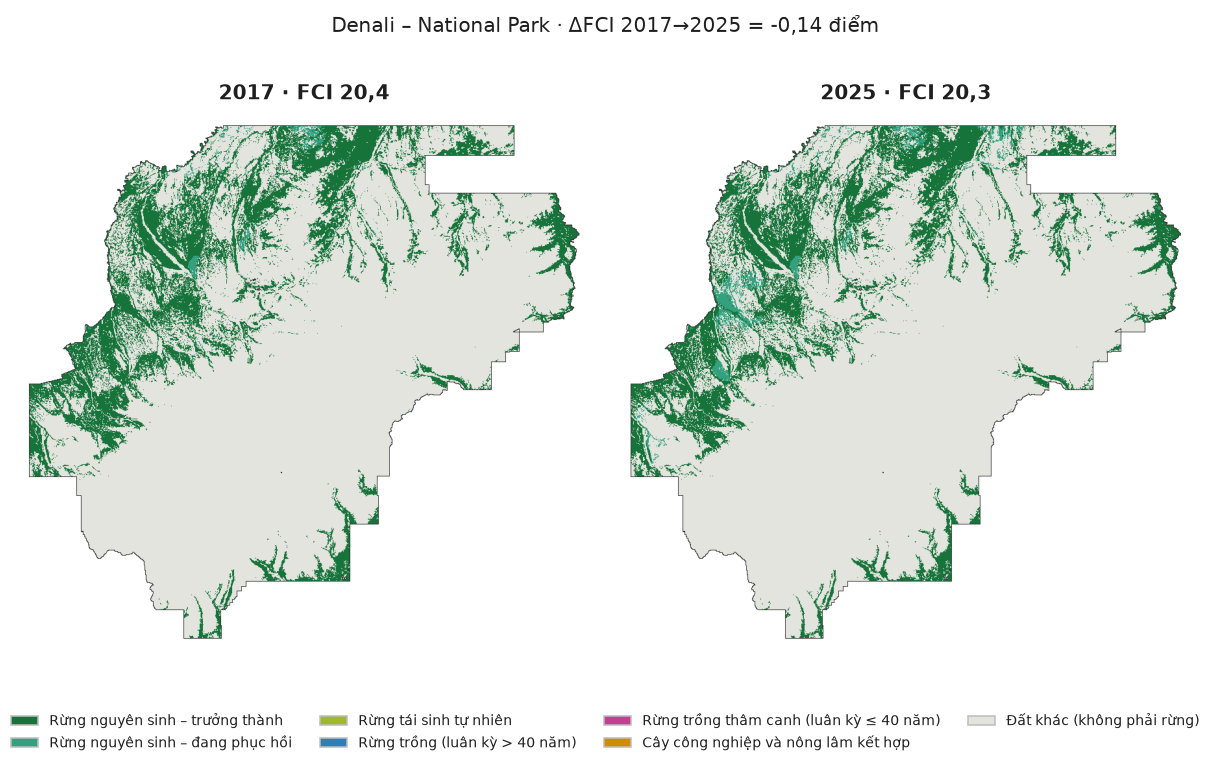

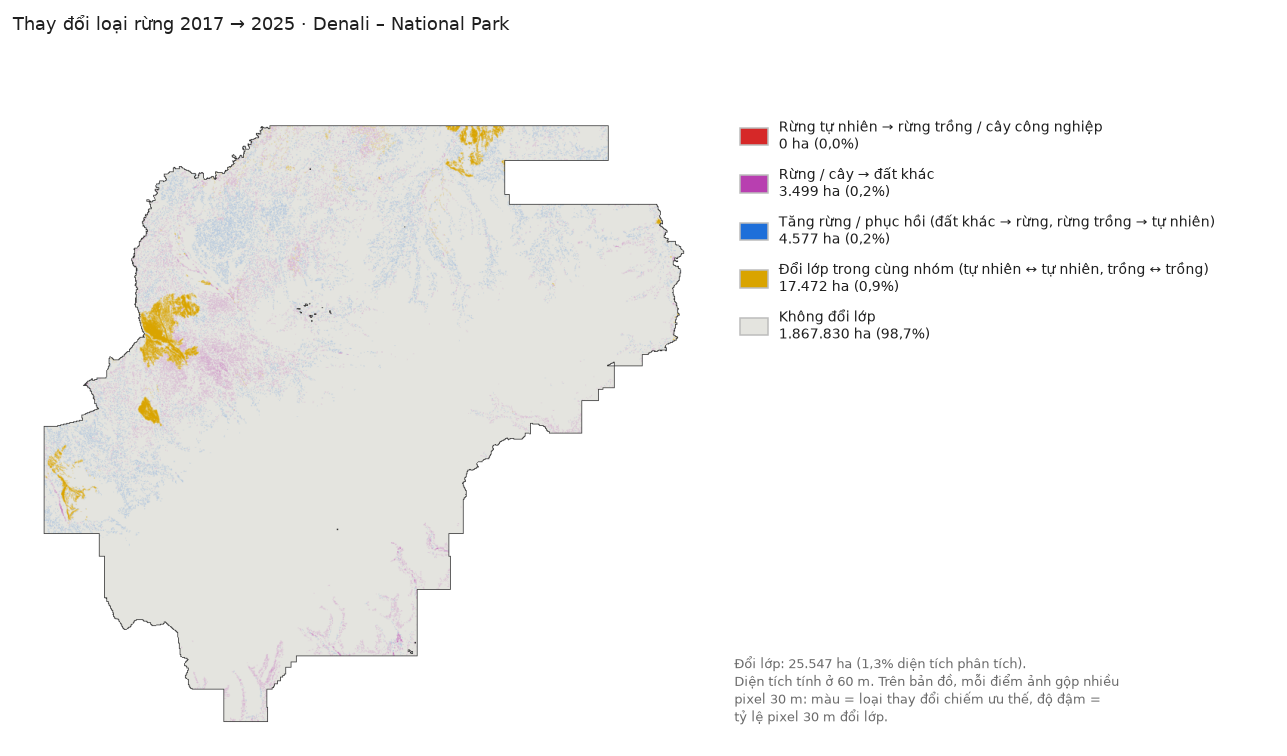

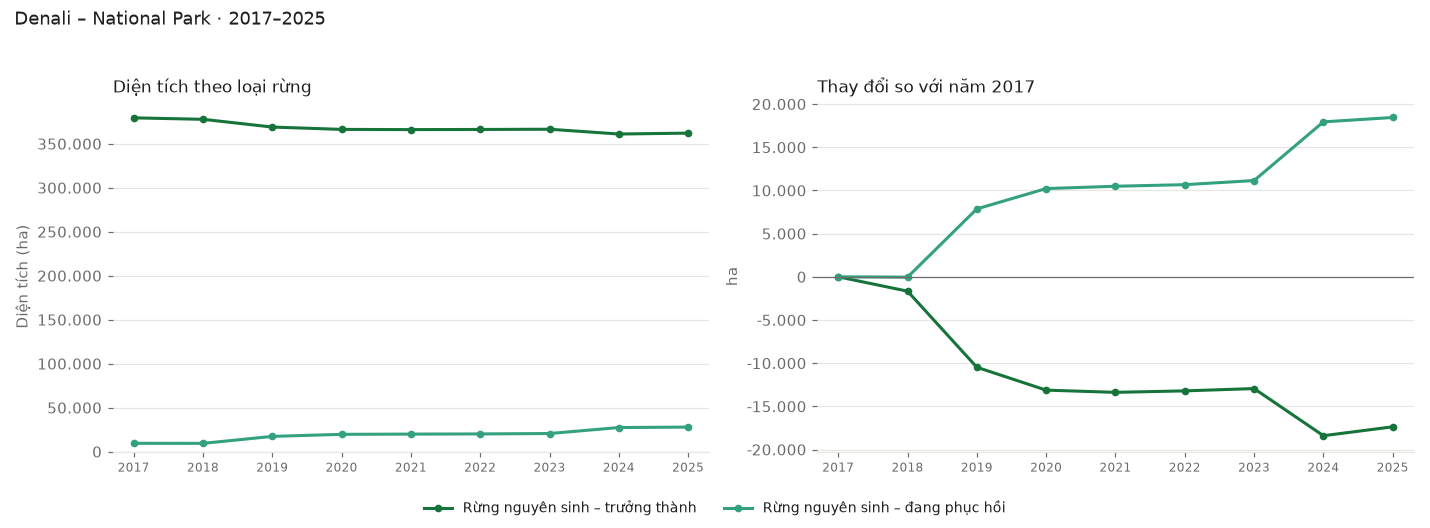

### Úc · 1. Munga-Thirri—Simpson Desert (National Park, WDPA 555759267)

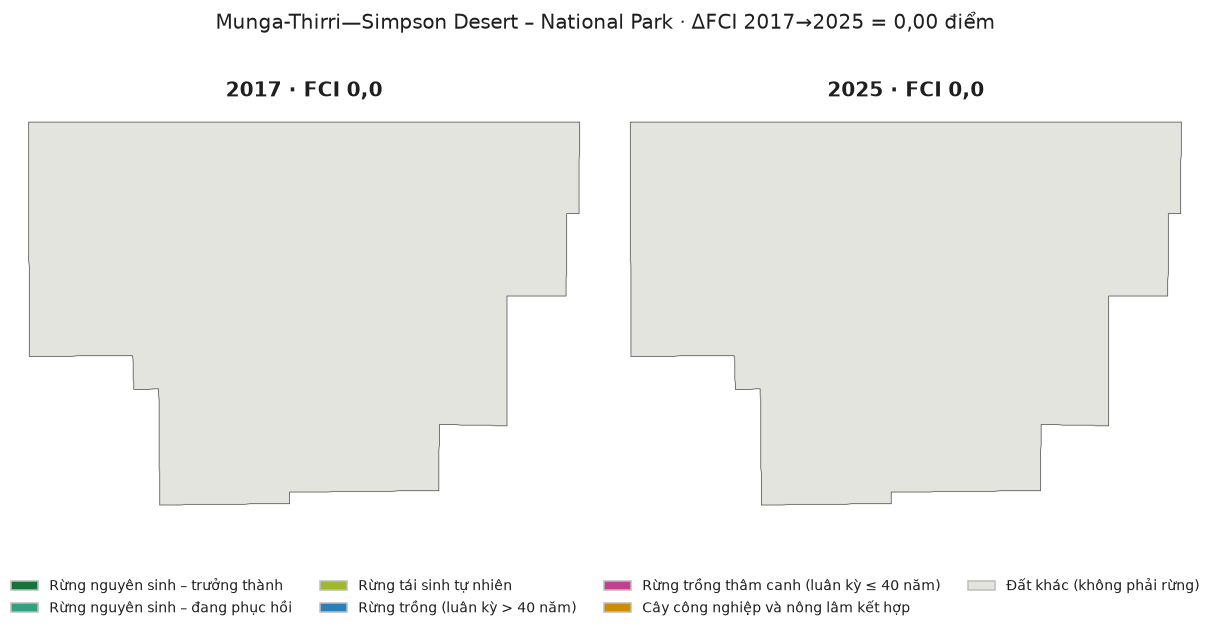

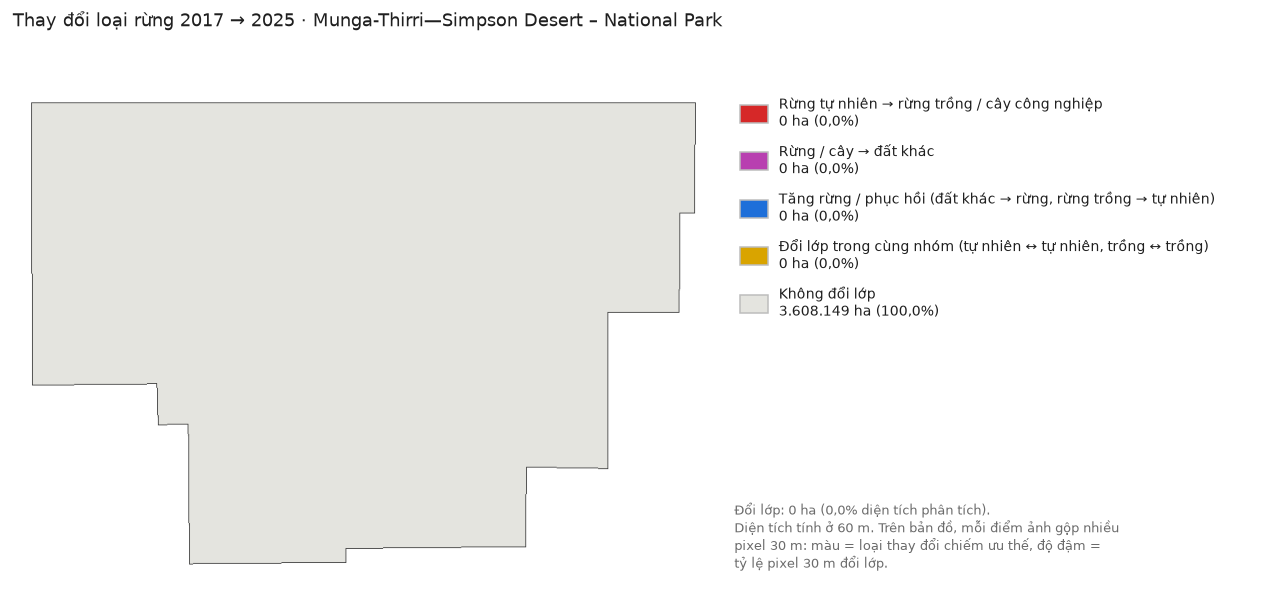

### Úc · 2. Great Victoria Desert (Nature Reserve, WDPA 126355)

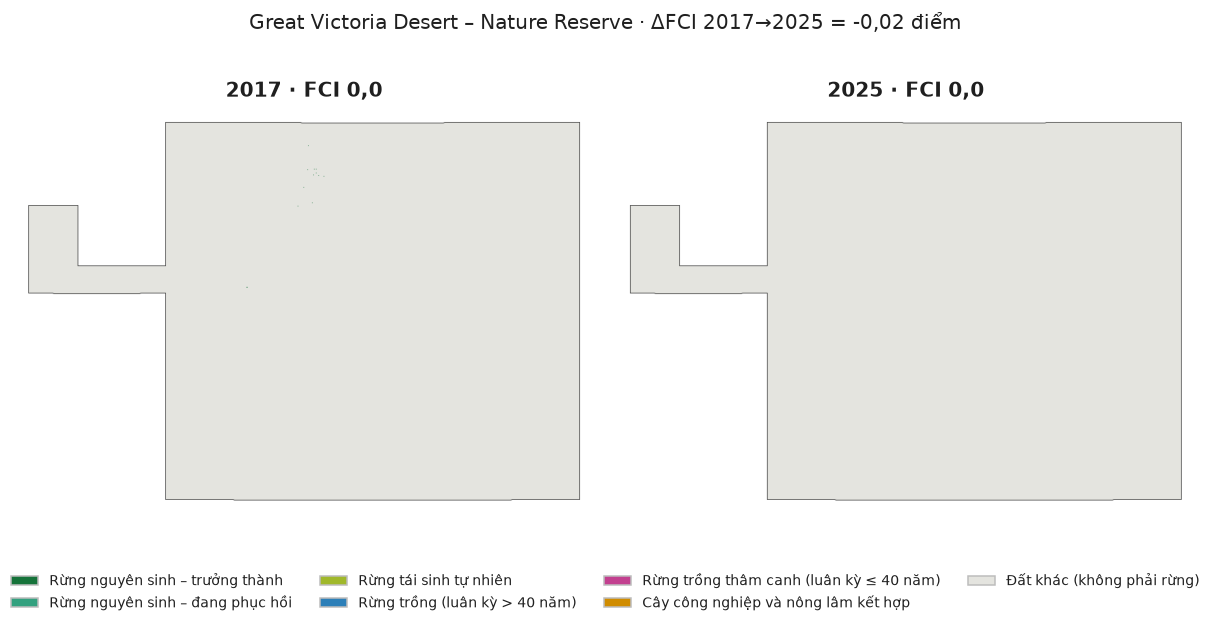

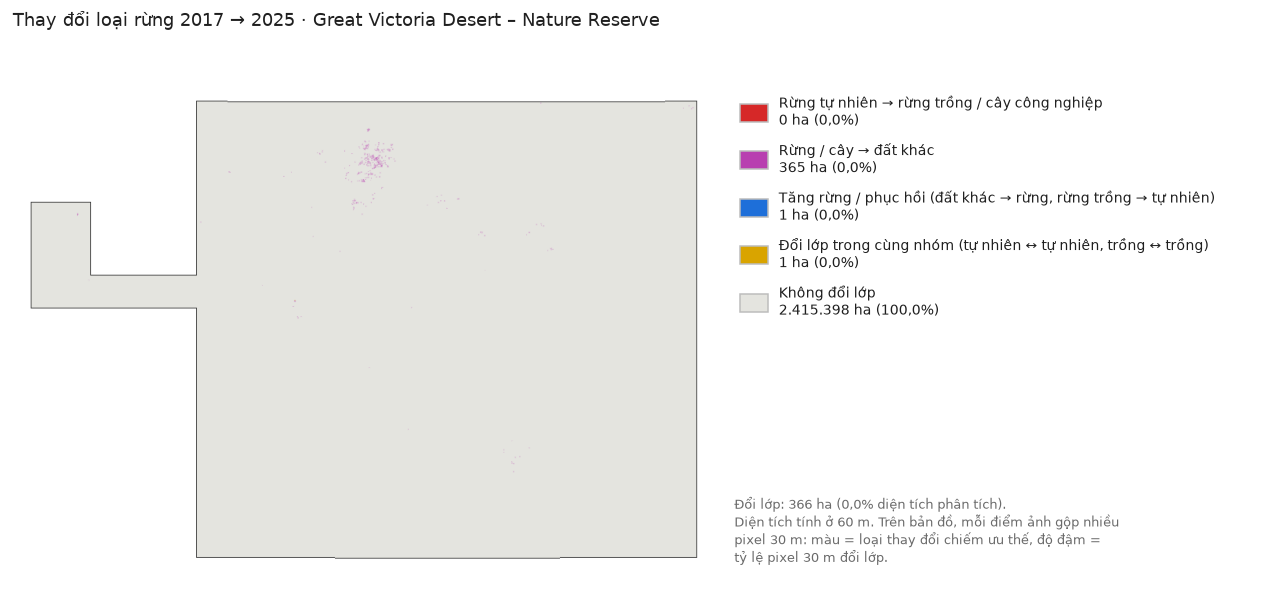

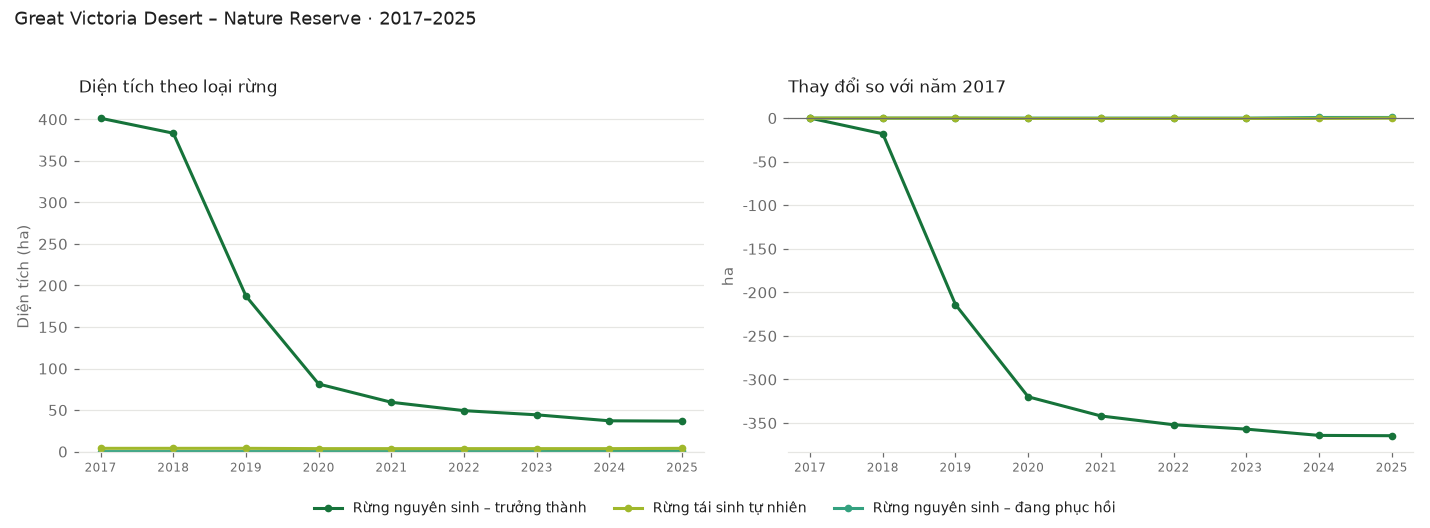

Các khu còn lại có trong báo cáo HTML


In [13]:
for iso in CFG["COUNTRIES"]:
    for pa in pas[pas.ISO3 == iso].head(CFG["SHOW_IN_NOTEBOOK"]).itertuples():
        display(Markdown(f"### {names[iso]} · {pa.RANK}. {pa.NAME} ({pa.DESIG_ENG}, WDPA {pa.SITE_ID})"))
        for k in ("map", "change", "chart"):
            if figures.get(pa.SITE_ID, {}).get(k):
                display(Image(filename=str(figures[pa.SITE_ID][k])))
print("Các khu còn lại có trong báo cáo HTML")

## 7. Báo cáo HTML

- `docs/index.html` (GitHub Pages): ảnh để thành file riêng trong `docs/img/` (256 màu, tải dần khi cuộn), nên trang nhẹ.
  Cần mở kèm thư mục `img/`.
- `outputs/bao_cao_FCI_3_nuoc.html`: một file duy nhất, ảnh nhúng sẵn (base64), để gửi đi hoặc mở riêng.

In [14]:
kw = dict(cfg=CFG, pas=pas, areas=areas, years=CFG["YEARS"], ind=ind, table=table, rank=rank, groups=groups,
          tests=tests, figures=figures, country_figs=country_figs, overview=overview, transitions=transitions,
          fci=fci, failed={**failed, **failed_tr})
pages = compare_report.build_report(CFG["PAGES_DIR"] / "index.html", embed=False, **kw)
(CFG["PAGES_DIR"] / ".nojekyll").touch()
single = compare_report.build_report(CFG["OUT"] / "bao_cao_FCI_3_nuoc.html", embed=True, **kw)
img_mb = sum(f.stat().st_size for f in (CFG["PAGES_DIR"] / "img").glob("*.png")) / 1e6
print(f"{pages} ({pages.stat().st_size / 1e6:.1f} MB + img/ {img_mb:.1f} MB)")
print(f"{single} ({single.stat().st_size / 1e6:.1f} MB)")

C:\Users\gfd\Documents\Claude\Projects\2026.11.07 ForTy compare\docs\index.html (0.3 MB + img/ 10.8 MB)
C:\Users\gfd\Documents\Claude\Projects\2026.11.07 ForTy compare\outputs\bao_cao_FCI_3_nuoc.html (14.6 MB)
